# 06 · Shortcut audit: why are the scores so high?

In Milestone 2 even Logistic Regression scored 99.99% on the provided columns. When a simple model is nearly perfect, it usually means **some inputs give the label away**. A model can then be "right" for reasons that have nothing to do with phishing. That's called a **shortcut**.

This notebook checks four things:
1. Where each column comes from (the URL, the web page, or outside statistics).
2. How well each column separates the classes **on its own**.
3. How far a **one-line rule** gets, with no model at all.
4. How accuracy changes when whole groups of columns are removed.

In [1]:
import matplotlib.pyplot as plt
import pandas as pd
from sklearn.metrics import roc_auc_score
from xgboost import XGBClassifier

from phishguard.data import load_clean, TARGET
from phishguard.split import get_splits
from phishguard.columns import COLUMN_GROUPS, URL_COLUMNS, STATISTIC_COLUMNS, PAGE_COLUMNS
from phishguard.modeling import fit_and_test
from phishguard.evaluate import evaluate, save_result

df = load_clean()
splits = get_splits(df)
train_idx, val_idx, test_idx = splits
y = df[TARGET]
X = df.drop(columns=TARGET).select_dtypes("number")

## 1. Where the columns come from

| Group | Count | What it is | Can our app compute it from a typed URL? |
|---|---|---|---|
| URL | 19 | Counts and flags from the URL string | Yes |
| statistic | 3 | Scores against outside reference data, e.g. `URLSimilarityIndex` = similarity to a list of known legitimate URLs | No |
| page | 28 | Counted in the downloaded HTML (lines of code, images, forms, …) | No, it would have to download the page |

In [2]:
{group: len(cols) for group, cols in COLUMN_GROUPS.items()}

{'URL': 19, 'statistic': 3, 'page': 28}

## 2. How well does each column separate the classes on its own?

**Single-column ROC-AUC:** use the column's raw value as the score. 0.5 means useless, 1.0 means the column alone separates the classes perfectly. We report `max(AUC, 1 − AUC)`, so that columns pointing the "other way" count too.

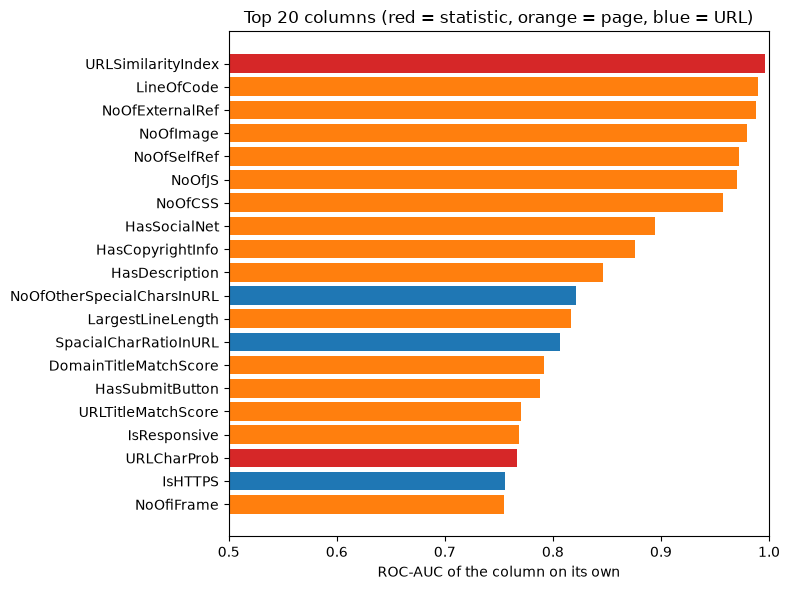

In [3]:
group_of = {c: g for g, cols in COLUMN_GROUPS.items() for c in cols}
auc = pd.DataFrame({
    "single_column_auc": [max(a, 1 - a) for a in (roc_auc_score(y, X[c]) for c in X.columns)],
    "group": [group_of[c] for c in X.columns],
}, index=X.columns).sort_values("single_column_auc", ascending=False)

top = auc.head(20).iloc[::-1]
colors = top["group"].map({"URL": "tab:blue", "statistic": "tab:red", "page": "tab:orange"})
plt.figure(figsize=(8, 6))
plt.barh(top.index, top["single_column_auc"], color=colors)
plt.xlim(0.5, 1.0)
plt.xlabel("ROC-AUC of the column on its own")
plt.title("Top 20 columns (red = statistic, orange = page, blue = URL)")
plt.tight_layout()
plt.show()

In [4]:
auc.head(10).round(4)

,single_column_auc,group
URLSimilarityIndex,0.9961,statistic
LineOfCode,0.9903,page
NoOfExternalRef,0.9880,page
NoOfImage,0.9796,page
NoOfSelfRef,0.9724,page
NoOfJS,0.9708,page
NoOfCSS,0.9576,page
HasSocialNet,0.8947,page
HasCopyrightInfo,0.8756,page
HasDescription,0.8462,page


- `URLSimilarityIndex` alone has AUC **0.996**.
- The next six are all **page** columns (`LineOfCode`, `NoOfExternalRef`, `NoOfImage`, …), each above 0.95.
- The best **URL** column only reaches about 0.82.

## 3. One-line rules (test set, no model)

In [5]:
t = df.loc[test_idx]
no_prefix = t["URL"].str.replace(r"^https?://", "", regex=True)
rules = {
    "URLSimilarityIndex < 100  → phishing": t["URLSimilarityIndex"] < 100,
    "URL doesn't start with https://www.  → phishing": ~t["URL"].str.startswith("https://www."),
    "IsHTTPS = 0  → phishing": t["IsHTTPS"] == 0,
    "URL has a path or query  → phishing": no_prefix.str.contains(r"[/?]"),
}
pd.DataFrame({
    rule: evaluate(y.loc[test_idx], pred.astype(int)) for rule, pred in rules.items()
}).T[["accuracy", "precision", "recall", "f1"]].round(4)

,accuracy,precision,recall,f1
URLSimilarityIndex < 100 → phishing,0.9972,1.0,0.9934,0.9967
URL doesn't start with https://www. → phishing,0.9916,1.0,0.9803,0.9900
IsHTTPS = 0 → phishing,0.7709,1.0,0.4601,0.6302
URL has a path or query → phishing,0.7282,1.0,0.3594,0.5288


Two rules that need no machine learning at all score **99.72%** and **99.16%**. That's above several published models.

Why the second rule works so well:

In [6]:
starts = df["URL"].str.startswith("https://www.")
starts.groupby(y.map({0: "legitimate", 1: "phishing"})).mean().rename("share starting with https://www.")

is_phishing
legitimate    1.000000
phishing      0.024085
Name: share starting with https://www., dtype: float64

**Every** legitimate URL in PhiUSIIL starts with `https://www.` and has no path: the legitimate side is a list of homepages. Only 2.4% of phishing URLs look like that. In the real world, phishing sites use HTTPS and `www.` too, so this rule would fail.

## 4. The prefix hides inside the "URL" columns too

Removing `IsHTTPS` isn't enough. `URLLength` minus the characters the dataset counts (letters, digits, specials, `=`, `?`, `&`) leaves exactly the characters that were never counted, and those mostly belong to the prefix:

In [7]:
counted = X[["NoOfLettersInURL", "NoOfDegitsInURL", "NoOfOtherSpecialCharsInURL",
             "NoOfEqualsInURL", "NoOfQMarkInURL", "NoOfAmpersandInURL"]].sum(axis=1)
leftover = (X["URLLength"] - counted).rename("URLLength − counted characters")
leftover.groupby(y.map({0: "legitimate", 1: "phishing"})).describe()[["mean", "min", "50%", "max"]]

,mean,min,50%,max
is_phishing,,,,
legitimate,12.000119,12.0,12.0,16.0
phishing,9.227477,7.0,8.0,136.0


For legitimate URLs the leftover is **12**: the length of `https://www.`. For phishing it's usually 7, 8 or 11 (`http://`, `https://`, `http://www.`). A tree model can read the prefix from these counts.

## 5. Removing groups of columns

Same XGBoost settings each time, same split, tested once.

In [8]:
column_sets = {
    "all 50 columns": list(X.columns),
    "without URLSimilarityIndex": [c for c in X.columns if c != "URLSimilarityIndex"],
    "page columns only": PAGE_COLUMNS,
    "statistic columns only": STATISTIC_COLUMNS,
    "URL columns only": URL_COLUMNS,
    "URL columns without IsHTTPS": [c for c in URL_COLUMNS if c != "IsHTTPS"],
}
rows = []
for name, cols in column_sets.items():
    model = XGBClassifier(max_depth=6, n_estimators=300, learning_rate=0.1, n_jobs=-1, random_state=42)
    _, threshold, m = fit_and_test(model, X[cols], y, splits)
    save_result(f"XGBoost: {name}", name, threshold, m, group="m3_columns")
    rows.append({"columns": name, "n": len(cols), "accuracy": m["accuracy"], "roc_auc": m["roc_auc"], "errors": m["fp"] + m["fn"]})
pd.DataFrame(rows).round(5)

,columns,n,accuracy,roc_auc,errors
0,all 50 columns,50,1.00000,1.00000,0
1,without URLSimilarityIndex,49,0.99974,1.00000,9
2,page columns only,28,0.99638,0.99996,127
3,statistic columns only,3,0.99693,0.99700,108
4,URL columns only,19,0.99752,0.99864,87
5,URL columns without IsHTTPS,18,0.99559,0.99849,155


## What we learned
1. **Page columns alone give 99.6%.** They measure what the crawler downloaded; legitimate homepages are big, and many phishing pages were already taken down or are tiny. That says more about how the data was collected than about phishing. Our app can't use them anyway.
2. **`URLSimilarityIndex` alone gives 99.7%** with a one-line rule. It compares the URL to a list of legitimate sites, which is close to looking up the answer.
3. **The URL columns still give 99.6% without `IsHTTPS`,** because the counts reveal the `https://www.` prefix.
4. **Every legitimate URL is a bare `https://www.` homepage.** "Doesn't start with `https://www.`" alone scores 99.2%.

So the near-perfect scores mostly measure **how PhiUSIIL was built**, not how well phishing can be detected. Notebook 07 measures what's left when the URL-level shortcuts are removed.